In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv("StudentsPerformance.csv")
df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.shape

(1000, 8)

In [5]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [7]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [8]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [9]:
df.isnull().sum().sum()

np.int64(0)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.drop_duplicates()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [12]:
df.shape

(1000, 8)

In [13]:
df["average_score"] = df[["math score", "reading score", "writing score"]].mean(axis=1)
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333


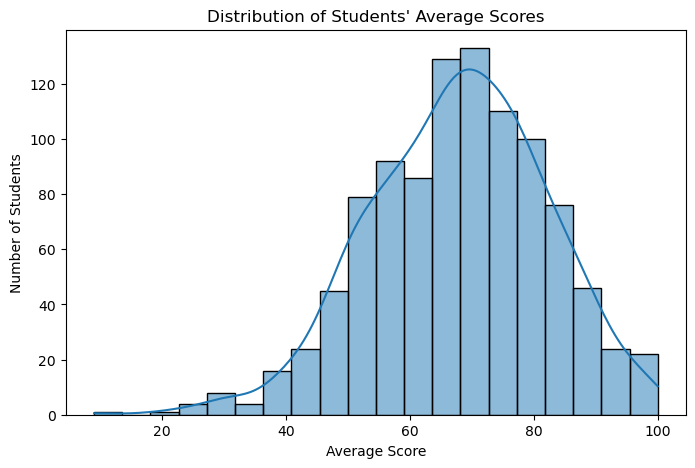

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(df["average_score"], bins=20, kde=True)

plt.title("Distribution of Students' Average Scores")
plt.xlabel("Average Score")
plt.ylabel("Number of Students")
plt.show()

In [15]:
gender_scores = df.groupby("gender")[["math score", "reading score", "writing score"]].mean()
print(gender_scores)

        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203


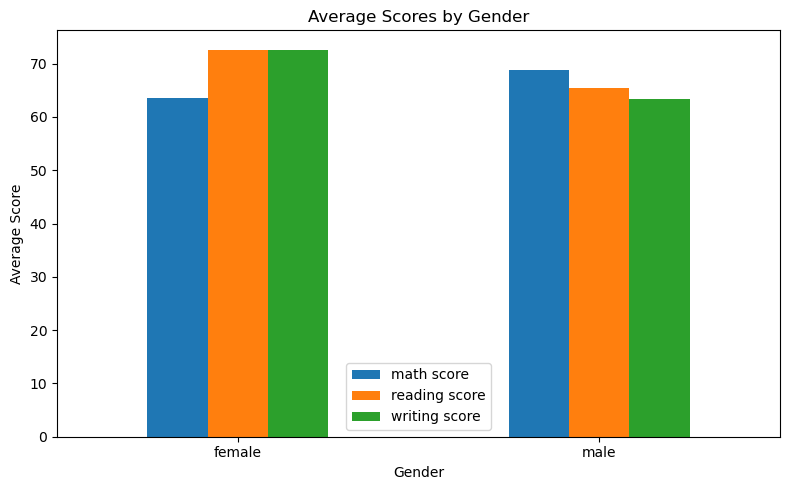

In [16]:
gender_scores.plot(kind="bar", figsize=(8, 5))
plt.title("Average Scores by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
prep_scores = df.groupby("test preparation course")[["math score", "reading score", "writing score", "average_score"]].mean()
print(prep_scores)

                         math score  reading score  writing score  \
test preparation course                                             
completed                 69.695531      73.893855      74.418994   
none                      64.077882      66.534268      64.504673   

                         average_score  
test preparation course                 
completed                    72.669460  
none                         65.038941  


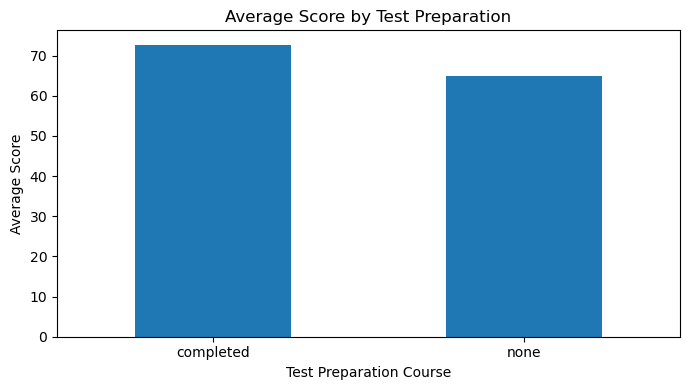

In [18]:
prep_scores["average_score"].plot(kind="bar",figsize=(7, 4))
plt.title("Average Score by Test Preparation")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
male_math = df[df["gender"] == "male"]["math score"]
female_math = df[df["gender"] == "female"]["math score"]
t_stat, p_value = stats.ttest_ind(male_math,female_math,equal_var=False)
print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 5.398000564160736
P-value: 8.420838109090415e-08


In [20]:
alpha = 0.05
if p_value < alpha:
    print("Reject the Null Hypothesis")
    print("There is a significant difference in maths scores.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("There is no statistically significant difference in maths scores.")

Reject the Null Hypothesis
There is a significant difference in maths scores.


In [21]:
completed = df[df["test preparation course"] == "completed"]["math score"]
none = df[df["test preparation course"] == "none"]["math score"]
t_stat, p_value = stats.ttest_ind(completed,none,equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 5.786983157907755
P-value: 1.0425616722069513e-08


In [22]:
if p_value < 0.05:
    print("Reject the Null Hypothesis")
    print("There is a significant difference in maths scores.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("There is no statistically significant difference in maths scores.")

Reject the Null Hypothesis
There is a significant difference in maths scores.


In [23]:
correlation, p_value = stats.pearsonr(df["math score"],df["reading score"])
print("Correlation Coefficient:", correlation)
print("P-value:", p_value)

Correlation Coefficient: 0.817579663672054
P-value: 1.7877531099061487e-241


In [24]:
if p_value < 0.05:
    print("Reject the Null Hypothesis")
    print("There is a statistically significant linear relationship.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("There is no statistically significant linear relationship.")

Reject the Null Hypothesis
There is a statistically significant linear relationship.


In [26]:
math_scores = df["math score"].dropna()
mean_score = math_scores.mean()
std_error = stats.sem(math_scores)
confidence_interval = stats.t.interval(confidence=0.95,df=len(math_scores) - 1,loc=mean_score,scale=std_error)
print("Mean Maths Score:", mean_score)
print("95% Confidence Interval:", confidence_interval)

Mean Maths Score: 66.089
95% Confidence Interval: (np.float64(65.14805983128305), np.float64(67.02994016871695))


In [27]:
score_columns = ["math score","reading score","writing score"]
correlation_matrix = df[score_columns].corr()
print(correlation_matrix)

               math score  reading score  writing score
math score       1.000000       0.817580       0.802642
reading score    0.817580       1.000000       0.954598
writing score    0.802642       0.954598       1.000000


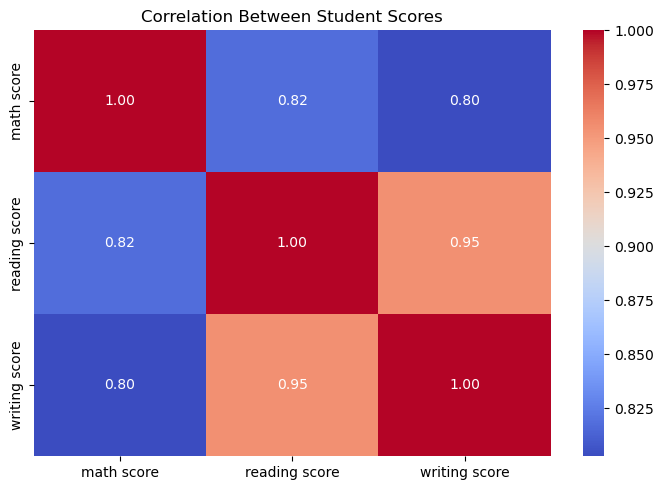

In [28]:
plt.figure(figsize=(7, 5))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Between Student Scores")
plt.tight_layout()
plt.show()

In [30]:
results = []
# Test 1: Gender and Maths Scores
male_math = df[df["gender"] == "male"]["math score"]
female_math = df[df["gender"] == "female"]["math score"]
t1, p1 = stats.ttest_ind(male_math,female_math,equal_var=False)

results.append({"Hypothesis": "Gender vs Maths Score","Test": "Welch's t-test","Statistic": t1,"P-value": p1,"Decision": "Reject H0" if p1 < 0.05 else "Fail to Reject H0"})

# Test 2: Preparation and Maths Scores
completed = df[df["test preparation course"] == "completed"]["math score"]
none = df[df["test preparation course"] == "none"]["math score"]
t2, p2 = stats.ttest_ind(completed,none,equal_var=False)
results.append({"Hypothesis": "Preparation vs Maths Score","Test": "Welch's t-test","Statistic": t2,"P-value": p2,"Decision": "Reject H0" if p2 < 0.05 else "Fail to Reject H0"})

# Test 3: Maths and Reading Correlation
r, p3 = stats.pearsonr(df["math score"],df["reading score"])
results.append({"Hypothesis": "Maths vs Reading Score","Test": "Pearson Correlation","Statistic": r,"P-value": p3,"Decision": "Reject H0" if p3 < 0.05 else "Fail to Reject H0"})
results_df = pd.DataFrame(results)
results_df

,Hypothesis,Test,Statistic,P-value,Decision
0,Gender vs Maths Score,Welch's t-test,5.398001,8.420838e-08,Reject H0
1,Preparation vs Maths Score,Welch's t-test,5.786983,1.042562e-08,Reject H0
2,Maths vs Reading Score,Pearson Correlation,0.817580,1.787753e-241,Reject H0


In [33]:
results_df.to_csv("Students_Performance_Hypothesis_Results.csv",index=False)
print("Results saved successfully!")

Results saved successfully!


In [34]:
df.to_csv("Students_Performance_Analyzed.csv",index=False)
print("Analyzed dataset saved successfully!")

Analyzed dataset saved successfully!


## Conclusion

The Students Performance dataset was analyzed using Python to understand students' academic performance.

Exploratory Data Analysis was performed to examine the distribution of scores and compare academic performance across different groups.

Hypothesis testing was conducted using Welch's independent samples t-test to compare maths scores by gender and test preparation status. Pearson correlation was used to examine the relationship between maths and reading scores.

A 5% significance level was used to evaluate the statistical tests. The results help identify statistically significant differences and relationships in students' academic performance.

Overall, this analysis demonstrates how statistical methods can be used to investigate research questions and support data-driven conclusions.